# Data Preprocessing: Analisis Tren Belanja Pelanggan Ritel

**Penyusun:** [Kesia Fathin] - [3022410046]
**Partner (pemberi kasus):** [Siti Fatimah] - [3022410054]
**Dataset:** `Shopping_Trends_dataset_kotor.csv` (120 baris, 14 variabel), diturunkan dari *Customer Shopping Trends Dataset* (Kaggle) dan sengaja dibuat kotor.

**Tujuan analisis (dari partner):** menyiapkan data bersih untuk (a) segmentasi pelanggan dan (b) analisis faktor yang memengaruhi *Review Rating*.

Setiap tahap dijelaskan dengan format **Input - Proses - Output**. Urutan: eksplorasi - cleansing (duplikat, tipe data, inkonsistensi kategori, nilai tidak valid, penyamaan satuan, outlier) - missing value - transformasi (agregasi, encoding, diskretisasi, normalisasi) - reduksi dimensi (seleksi dan ekstraksi fitur).

In [1]:
import os, re, json, warnings, difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 170)
sns.set_theme(style="whitegrid")
os.makedirs("gambar", exist_ok=True); os.makedirs("hasil", exist_ok=True)
M = {}   # angka-angka untuk laporan

def simpan_gambar(nama):
    plt.tight_layout(); plt.savefig(f"gambar/{nama}.png", dpi=150, bbox_inches="tight"); plt.show()

FILE = "NamaPartner_NIMPartner.csv"   # ganti dengan [Nama Partner]_[NIM].csv
df_raw = pd.read_csv(FILE)
df = df_raw.copy()
M["shape_awal"] = list(df.shape)
print("Ukuran data awal:", df.shape)

Ukuran data awal: (120, 14)


## 1. Eksplorasi dan Pemeriksaan Kualitas Data
**Input:** data mentah dari partner (120 baris x 14 kolom).
**Proses:** `info()`, `describe()`, hitung missing value, duplikat, dan jumlah nilai unik tiap variabel kategorik.
**Output:** daftar masalah kualitas data.

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Customer ID                120 non-null    int64
 1   Age                        111 non-null    str  
 2   Gender                     120 non-null    str  
 3   Location                   112 non-null    str  
 4   Category                   120 non-null    str  
 5   Season                     115 non-null    str  
 6   Payment Method             112 non-null    str  
 7   Shipping Type              120 non-null    str  
 8   Subscription Status        120 non-null    str  
 9   Frequency of Purchases     120 non-null    str  
 10  Purchase Amount (USD)      104 non-null    str  
 11  Review Rating              113 non-null    str  
 12  Previous Purchases         120 non-null    int64
 13  Previous Purchases Period  120 non-null    str  
dtypes: int64(2), str(12)
memory usage: 13

,Customer ID,Age,Gender,Location,Category,Season,Payment Method,Shipping Type,Subscription Status,Frequency of Purchases,Purchase Amount (USD),Review Rating,Previous Purchases,Previous Purchases Period
0,3276,NaN,Female,Alabama,Clothing,Summer,Debit Card,2-Day Shipping,No,Weekly,NaN,2.6,1,Monthly
1,1461,NaN,Male,Pennsylvania,Footwear,Fall,Vnemo,Standard,No,Bi-Weekly,85,4.6,33,12 Months
2,311,56,Male,Montana,Clothing,Winter,Cash,Standard,Yes,Fortnightly,85,4.6,50,12 Months
3,1210,41,Male,Pennsylania,Clothing,Winter,Bank Transfer,Next Day Air,No,Monthly,62,3.8,16,12 Months
4,2953,230,Female,Alabama,Accessories,Spring,Debit Card,Next Day Air,No,Monthly,24,4.9,1,Monthly


,missing,persen
Purchase Amount (USD),16,13.33
Age,9,7.50
Location,8,6.67
Payment Method,8,6.67
Review Rating,7,5.83
Season,5,4.17


Baris duplikat: 5 | Customer ID berulang: 5


,Jumlah nilai unik (awal)
Gender,9
Location,52
Category,14
Season,7
Payment Method,18
Shipping Type,10
Subscription Status,2
Frequency of Purchases,7
Previous Purchases Period,2


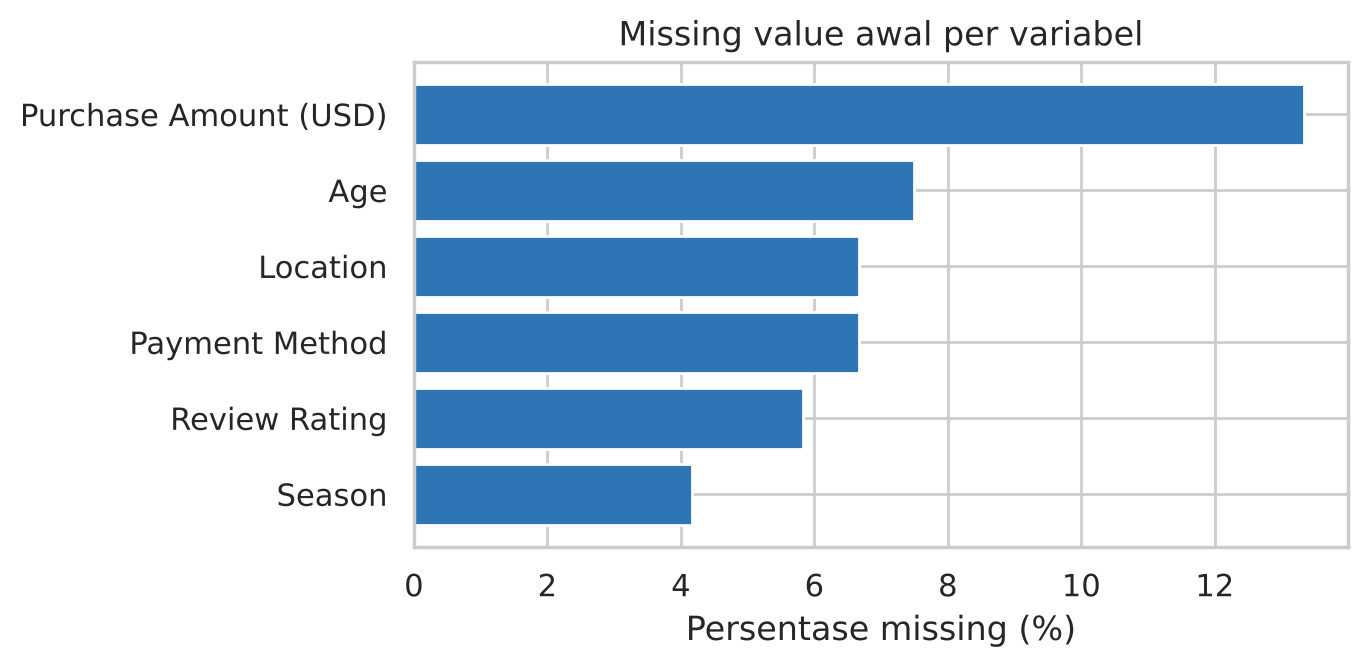

In [2]:
df.info()
display(df.head())
M["dtype_awal"] = {k: str(v) for k, v in df.dtypes.items()}

miss = df.isna().sum()
tbl = pd.DataFrame({"missing": miss, "persen": (miss / len(df) * 100).round(2)})
tbl_miss = tbl[tbl.missing > 0].sort_values("persen", ascending=False)
display(tbl_miss)
M["missing_awal"] = {k: [int(v.missing), float(v.persen)] for k, v in tbl_miss.iterrows()}
M["duplikat_awal"] = int(df.duplicated().sum())
M["id_duplikat_awal"] = int(df["Customer ID"].duplicated().sum())
print("Baris duplikat:", M["duplikat_awal"], "| Customer ID berulang:", M["id_duplikat_awal"])

kat = ["Gender", "Location", "Category", "Season", "Payment Method", "Shipping Type", "Subscription Status",
       "Frequency of Purchases", "Previous Purchases Period"]
M["nunique_awal"] = {k: int(df[k].nunique()) for k in kat}
display(pd.Series(M["nunique_awal"], name="Jumlah nilai unik (awal)").to_frame())

m = tbl_miss.sort_values("persen")
plt.figure(figsize=(7, 3.5)); plt.barh(m.index, m.persen, color="#2E75B6")
plt.xlabel("Persentase missing (%)"); plt.title("Missing value awal per variabel")
simpan_gambar("01_missing_awal")

In [3]:
# Hanya Customer ID dan Previous Purchases yang terbaca numerik. Age, Purchase Amount, Review Rating terbaca teks.
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Customer ID,120.0,1950.15,1183.402697,22.0,992.75,1787.5,2995.75,3892.0
Previous Purchases,120.0,29.95,67.922948,-6.0,4.00,19.0,33.00,480.0


## 2. Data Cleansing

### 2.1 Data Duplikat
**Input:** data mentah (120 baris). **Proses:** `duplicated()` lalu `drop_duplicates()`. **Output:** setiap `Customer ID` muncul sekali.

In [4]:
M["dup_baris"] = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
M["shape_setelah_dup"] = list(df.shape)
print("Duplikat dihapus:", M["dup_baris"], "| ukuran:", df.shape, "| Customer ID unik:", df["Customer ID"].is_unique)

Duplikat dihapus: 5 | ukuran: (115, 14) | Customer ID unik: True


### 2.2 Tipe Data Salah
**Input:** `Age`, `Purchase Amount (USD)`, `Review Rating` yang terbaca sebagai teks (ada `"49 years"`, `"$43"`, `"USD 78"`, desimal koma `"2,6"`).
**Proses:** mengganti koma desimal menjadi titik, mengambil angka dengan regex, lalu `to_numeric()`.
**Output:** ketiga kolom bertipe `float`.

In [5]:
def ke_angka(s):
    s = s.astype("string").str.replace(",", ".", regex=False)
    return pd.to_numeric(s.str.extract(r"(-?\d+\.?\d*)")[0], errors="coerce").astype(float)

M["tipe_salah"] = {}
for k in ["Age", "Purchase Amount (USD)", "Review Rating"]:
    s = df[k].astype("string")
    bermasalah = s.str.contains(r"[A-Za-z$,]", na=False)
    M["tipe_salah"][k] = {"jumlah": int(bermasalah.sum()), "contoh": s[bermasalah].head(4).tolist()}
    df[k] = ke_angka(df[k])
print(json.dumps(M["tipe_salah"], indent=1, ensure_ascii=False))
print(df[["Age", "Purchase Amount (USD)", "Review Rating"]].dtypes)

{
 "Age": {
  "jumlah": 4,
  "contoh": [
   "67 years",
   "49 years",
   "22 th",
   "27 th"
  ]
 },
 "Purchase Amount (USD)": {
  "jumlah": 5,
  "contoh": [
   "$43",
   "$48",
   "USD 92",
   "USD 78"
  ]
 },
 "Review Rating": {
  "jumlah": 3,
  "contoh": [
   "2,6",
   "3,7",
   "4,1"
  ]
 }
}
Age                      float64
Purchase Amount (USD)    float64
Review Rating            float64
dtype: object


### 2.3 Inkonsistensi Kategori
**Input:** variabel kategorik dengan huruf besar/kecil tidak seragam, spasi berlebih, salah ketik, sinonim (`M`, `Pria`, `Every 3 Months`, `Fortnightly`), dan penanda kosong `"-"`.
**Proses:**
1. Penanda kosong (`-`) diubah menjadi NaN.
2. `strip()` dan `lower()`, lalu dicocokkan ke daftar label baku.
3. Sinonim dipetakan manual; salah ketik dikoreksi dengan *fuzzy matching* (`difflib`, kemiripan >= 0,7).

**Output:** setiap variabel hanya berisi label baku.

In [6]:
PLACEHOLDER = {"-", "", "n/a", "na", "?", "null", "none"}
STATES = ["Alabama","Alaska","Arizona","Arkansas","California","Colorado","Connecticut","Delaware","Florida","Georgia","Hawaii","Idaho",
          "Illinois","Indiana","Iowa","Kansas","Kentucky","Louisiana","Maine","Maryland","Massachusetts","Michigan","Minnesota",
          "Mississippi","Missouri","Montana","Nebraska","Nevada","New Hampshire","New Jersey","New Mexico","New York","North Carolina",
          "North Dakota","Ohio","Oklahoma","Oregon","Pennsylvania","Rhode Island","South Carolina","South Dakota","Tennessee","Texas",
          "Utah","Vermont","Virginia","Washington","West Virginia","Wisconsin","Wyoming"]
KANON = {
    "Gender": ["Male", "Female"],
    "Location": STATES,
    "Category": ["Clothing", "Footwear", "Outerwear", "Accessories"],
    "Season": ["Spring", "Summer", "Fall", "Winter"],
    "Payment Method": ["Cash", "Credit Card", "Debit Card", "PayPal", "Venmo", "Bank Transfer"],
    "Shipping Type": ["Free Shipping", "Standard", "Express", "2-Day Shipping", "Next Day Air", "Store Pickup"],
    "Subscription Status": ["Yes", "No"],
    "Frequency of Purchases": ["Weekly", "Bi-Weekly", "Monthly", "Quarterly", "Annually"],
    "Previous Purchases Period": ["12 Months", "Monthly"],
}
SINONIM = {
    "Gender": {"m": "Male", "f": "Female", "pria": "Male", "wanita": "Female"},
    "Frequency of Purchases": {"every 3 months": "Quarterly", "fortnightly": "Bi-Weekly"},
}

def baku(nilai, kanon, sin):
    if pd.isna(nilai): return np.nan
    x = str(nilai).strip()
    if x.lower() in PLACEHOLDER: return np.nan
    low = re.sub(r"\s+", " ", x.lower())
    peta = {k.lower(): k for k in kanon}
    if low in sin: return sin[low]
    if low in peta: return peta[low]
    cocok = difflib.get_close_matches(low, list(peta), n=1, cutoff=0.7)
    return peta[cocok[0]] if cocok else "??" + x

M["kategori"] = {}
for k, kanon in KANON.items():
    asli = df[k].copy()
    na0 = int(asli.isna().sum())
    df[k] = asli.map(lambda v: baku(v, kanon, SINONIM.get(k, {})))
    tak_cocok = df[k].astype("string").str.startswith("??", na=False).sum()
    ubah = asli.notna() & df[k].notna() & (asli != df[k])
    plc = int(df[k].isna().sum() - na0)
    contoh = sorted({f"{a!r} -> {b!r}" for a, b in zip(asli[ubah], df.loc[ubah, k])})[:5]
    M["kategori"][k] = {"label_sebelum": int(asli.nunique()), "label_sesudah": int(df[k].nunique()), "sel_diubah": int(ubah.sum()),
                        "placeholder_jadi_nan": plc, "tak_cocok": int(tak_cocok), "contoh": contoh}
    print(f"{k}: {asli.nunique()} -> {df[k].nunique()} label | diubah {int(ubah.sum())} sel | placeholder->NaN {plc} | tak cocok {int(tak_cocok)}")
    assert tak_cocok == 0

Gender: 9 -> 2 label | diubah 13 sel | placeholder->NaN 0 | tak cocok 0
Location: 52 -> 41 label | diubah 12 sel | placeholder->NaN 0 | tak cocok 0
Category: 14 -> 4 label | diubah 13 sel | placeholder->NaN 0 | tak cocok 0
Season: 7 -> 4 label | diubah 4 sel | placeholder->NaN 2 | tak cocok 0
Payment Method: 18 -> 6 label | diubah 12 sel | placeholder->NaN 0 | tak cocok 0
Shipping Type: 10 -> 6 label | diubah 4 sel | placeholder->NaN 0 | tak cocok 0
Subscription Status: 2 -> 2 label | diubah 0 sel | placeholder->NaN 0 | tak cocok 0
Frequency of Purchases: 7 -> 5 label | diubah 33 sel | placeholder->NaN 0 | tak cocok 0
Previous Purchases Period: 2 -> 2 label | diubah 0 sel | placeholder->NaN 0 | tak cocok 0


### 2.4 Nilai Tidak Valid
**Input:** variabel numerik dengan aturan domain: `Age` 18-100, `Purchase Amount` > 0, `Review Rating` 1-5, `Previous Purchases` >= 0.
**Proses:** nilai di luar domain diubah menjadi NaN dan ditangani bersama missing value.
**Output:** semua nilai tersisa berada dalam domain.

In [7]:
aturan = {"Age": (18, 100), "Purchase Amount (USD)": (0.01, np.inf), "Review Rating": (1, 5), "Previous Purchases": (0, np.inf)}
M["tidak_valid"] = {}
df["Previous Purchases"] = df["Previous Purchases"].astype(float)
for k, (lo, hi) in aturan.items():
    salah = df[k].notna() & ~df[k].between(lo, hi)
    M["tidak_valid"][k] = {"jumlah": int(salah.sum()), "nilai": sorted(df.loc[salah, k].unique().tolist()), "aturan": f"{lo} sampai {hi}"}
    df.loc[salah, k] = np.nan
print(json.dumps(M["tidak_valid"], indent=1, ensure_ascii=False))

{
 "Age": {
  "jumlah": 4,
  "nilai": [
   -4.0,
   0.0,
   150.0,
   230.0
  ],
  "aturan": "18 sampai 100"
 },
 "Purchase Amount (USD)": {
  "jumlah": 1,
  "nilai": [
   -45.0
  ],
  "aturan": "0.01 sampai inf"
 },
 "Review Rating": {
  "jumlah": 3,
  "nilai": [
   -1.0,
   0.0,
   9.0
  ],
  "aturan": "1 sampai 5"
 },
 "Previous Purchases": {
  "jumlah": 2,
  "nilai": [
   -6.0,
   -3.0
  ],
  "aturan": "0 sampai inf"
 }
}


### 2.5 Penyamaan Satuan: Previous Purchases
**Input:** `Previous Purchases` dicatat dengan dua periode berbeda (`Previous Purchases Period` = `12 Months` atau `Monthly`), sehingga angkanya tidak sebanding.
**Proses:** mengubah ke satuan yang sama, yaitu per 12 bulan: nilai `Monthly` dikali 12. Kecocokan skala dicek dengan membandingkan median.
**Output:** kolom baru `Previous_Purchases_12M`; kolom `Previous Purchases` dan `Previous Purchases Period` dibuang.

In [8]:
bulanan = df["Previous Purchases Period"] == "Monthly"
med = {"12M_asli": float(df.loc[~bulanan, "Previous Purchases"].median()),
       "bulanan_asli": float(df.loc[bulanan, "Previous Purchases"].median()),
       "bulanan_x12": float((df.loc[bulanan, "Previous Purchases"] * 12).median()), "n_bulanan": int(bulanan.sum())}
M["satuan_prev"] = med
print(med)
df["Previous_Purchases_12M"] = df["Previous Purchases"] * np.where(bulanan, 12, 1)
df = df.drop(columns=["Previous Purchases", "Previous Purchases Period"])
display(df[["Previous_Purchases_12M"]].describe().T)

{'12M_asli': 25.0, 'bulanan_asli': 2.0, 'bulanan_x12': 24.0, 'n_bulanan': 26}


,count,mean,std,min,25%,50%,75%,max
Previous_Purchases_12M,113.0,65.707965,394.974246,2.0,12.0,24.0,36.0,4200.0


### 2.6 Deteksi dan Penanganan Outlier
**Input:** variabel numerik (`Age`, `Purchase Amount (USD)`, `Review Rating`, `Previous_Purchases_12M`).
**Proses:**
1. Deteksi dengan **IQR** dan **Z-score** (|z| > 3).
2. Menilai penyebab outlier. Pada `Purchase Amount`, nilai 4 digit kelipatan 100 diduga salah satuan (sen). Dibuktikan jika nilai/100 masuk ke rentang nilai normal, lalu dikoreksi dengan dibagi 100.
3. `Previous_Purchases_12M` di-*capping* pada batas atas IQR. Outlier `Age` dipertahankan karena masih mungkin sebagai usia manusia.

**Output:** data tanpa nilai ekstrem yang tidak wajar.

,Variabel,Batas bawah,Batas atas,Outlier IQR,Outlier Z>3,Maks
0,Age,-4.6,98.4,1,1,99.0
1,Purchase Amount (USD),-44.0,174.0,11,4,9900.0
2,Review Rating,1.4,5.9,0,0,4.9
3,Previous_Purchases_12M,-24.0,72.0,2,1,4200.0


{'jumlah': 11, 'nilai': [2100.0, 2800.0, 2900.0, 3500.0, 3800.0, 4500.0, 4900.0, 7200.0, 7300.0, 9700.0, 9900.0], 'semua_kelipatan_100': True, 'hasil_bagi_min': 21.0, 'hasil_bagi_maks': 99.0, 'rentang_normal': [20.0, 100.0]}
{'batas_atas': 72.0, 'jumlah': 2, 'nilai': [480.0, 4200.0], 'mean_sebelum': 65.71, 'mean_sesudah': 25.57}


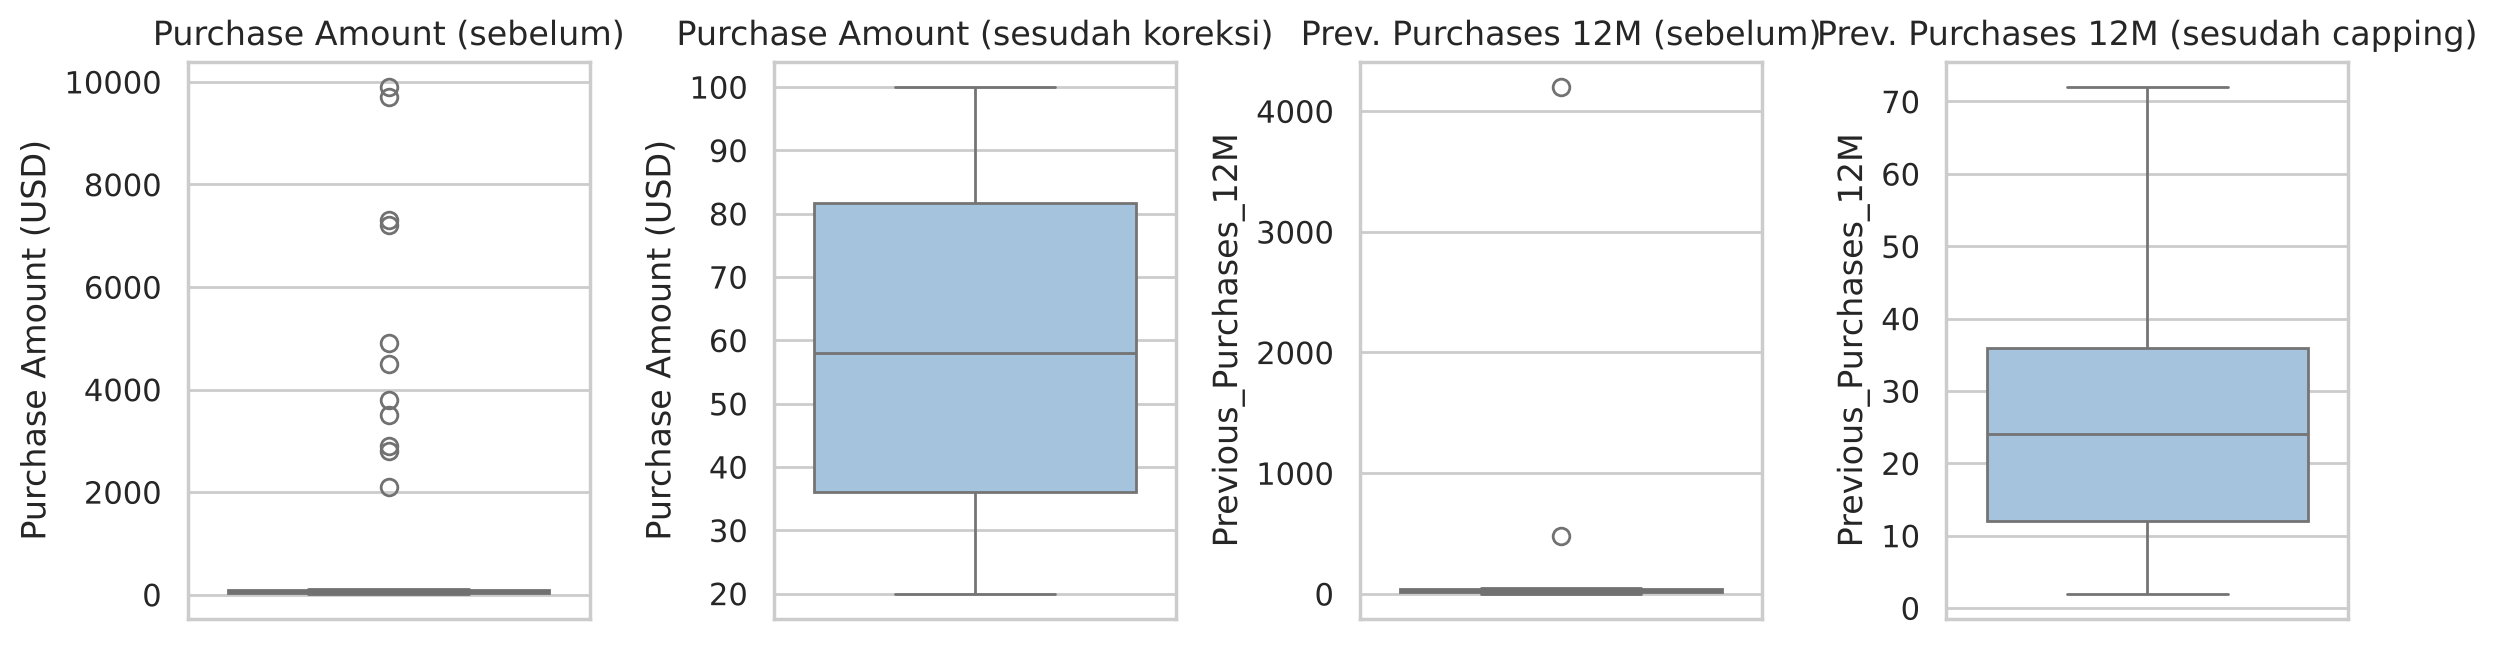

,Variabel,Batas bawah,Batas atas,Outlier IQR,Outlier Z>3,Maks
0,Age,-4.6,98.4,1,1,99.0
1,Purchase Amount (USD),-32.6,150.4,0,0,100.0
2,Review Rating,1.4,5.9,0,0,4.9
3,Previous_Purchases_12M,-24.0,72.0,0,2,72.0


In [9]:
def batas_iqr(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - 1.5 * i, q3 + 1.5 * i

kol_out = ["Age", "Purchase Amount (USD)", "Review Rating", "Previous_Purchases_12M"]
def tabel_outlier():
    baris = []
    for k in kol_out:
        lo, hi = batas_iqr(df[k]); z = (df[k] - df[k].mean()) / df[k].std()
        baris.append({"Variabel": k, "Batas bawah": round(float(lo), 1), "Batas atas": round(float(hi), 1),
                      "Outlier IQR": int(((df[k] < lo) | (df[k] > hi)).sum()), "Outlier Z>3": int((z.abs() > 3).sum()),
                      "Maks": round(float(df[k].max()), 1)})
    return pd.DataFrame(baris)

tbl_out = tabel_outlier(); display(tbl_out)
M["outlier_sebelum"] = tbl_out.to_dict("records")

fig, ax = plt.subplots(1, 4, figsize=(12, 3.4))
sns.boxplot(y=df["Purchase Amount (USD)"], ax=ax[0], color="#F4B183"); ax[0].set_title("Purchase Amount (sebelum)")
sns.boxplot(y=df["Previous_Purchases_12M"], ax=ax[2], color="#F4B183"); ax[2].set_title("Prev. Purchases 12M (sebelum)")

# --- Purchase Amount: dugaan salah satuan (sen)
a = df["Purchase Amount (USD)"]; lo_a, hi_a = batas_iqr(a)
besar = a > hi_a
normal = a[~besar & a.notna()]
bukti = {"jumlah": int(besar.sum()), "nilai": sorted(a[besar].tolist()),
         "semua_kelipatan_100": bool((a[besar] % 100 == 0).all()),
         "hasil_bagi_min": float((a[besar] / 100).min()), "hasil_bagi_maks": float((a[besar] / 100).max()),
         "rentang_normal": [float(normal.min()), float(normal.max())]}
M["amount_satuan"] = bukti; print(bukti)
M["amount_mean_sebelum"] = round(float(a.mean()), 2)
df.loc[besar, "Purchase Amount (USD)"] = a[besar] / 100
M["amount_mean_sesudah"] = round(float(df["Purchase Amount (USD)"].mean()), 2)

# --- Previous Purchases: capping
p = df["Previous_Purchases_12M"]; lo_p, hi_p = batas_iqr(p)
cap = p > hi_p
M["capping"] = {"batas_atas": float(hi_p), "jumlah": int(cap.sum()), "nilai": sorted(p[cap].tolist()),
                "mean_sebelum": round(float(p.mean()), 2)}
df["Previous_Purchases_12M"] = p.clip(upper=hi_p)
M["capping"]["mean_sesudah"] = round(float(df["Previous_Purchases_12M"].mean()), 2)
print(M["capping"])

sns.boxplot(y=df["Purchase Amount (USD)"], ax=ax[1], color="#9DC3E6"); ax[1].set_title("Purchase Amount (sesudah koreksi)")
sns.boxplot(y=df["Previous_Purchases_12M"], ax=ax[3], color="#9DC3E6"); ax[3].set_title("Prev. Purchases 12M (sesudah capping)")
simpan_gambar("02_outlier")

tbl_out2 = tabel_outlier(); display(tbl_out2)
M["outlier_sesudah"] = tbl_out2.to_dict("records")

## 3. Penanganan Missing Value
**Input:** data hasil cleansing. Missing value kini mencakup missing asli, penanda `"-"`, dan nilai tidak valid yang sudah diubah menjadi NaN.
**Proses:**
1. Menghitung jumlah dan persentase missing, baik numerik maupun kategorik.
2. Menghitung **statistik deskriptif**: mean, median, std, skewness untuk numerik; modus dan proporsinya untuk kategorik.
3. Aturan pemilihan imputasi berdasarkan statistik tersebut:
   - Numerik: |skewness| < 0,5 maka **mean** (distribusi simetris), selain itu **median**.
   - Kategorik: proporsi modus >= 25% maka **modus**; jika lebih kecil, modus tidak representatif sehingga dipakai kategori **"Tidak Diketahui"**.
4. Membandingkan statistik sebelum dan sesudah imputasi.

**Output:** dataset tanpa missing value (`hasil/data_bersih.csv`).

In [10]:
kol_num = ["Age", "Purchase Amount (USD)", "Review Rating", "Previous_Purchases_12M"]
kol_kat = ["Gender", "Location", "Category", "Season", "Payment Method", "Shipping Type", "Subscription Status", "Frequency of Purchases"]

miss2 = df.isna().sum()
tbl2 = pd.DataFrame({"missing": miss2, "persen": (miss2 / len(df) * 100).round(2)})
tbl2 = tbl2[tbl2.missing > 0].sort_values("persen", ascending=False); display(tbl2)
M["missing_sebelum_impute"] = {k: [int(v.missing), float(v.persen)] for k, v in tbl2.iterrows()}

st_num = df[kol_num].agg(["count", "mean", "median", "std", "min", "max", "skew"]).T.round(2); display(st_num)
M["stat_num_sebelum"] = st_num.to_dict("index")

st_kat = {}
for k in tbl2.index.intersection(kol_kat):
    vc = df[k].value_counts()
    st_kat[k] = {"modus": vc.index[0], "frekuensi": int(vc.iloc[0]), "persen": round(float(vc.iloc[0] / vc.sum() * 100), 1),
                 "n_label": int(len(vc))}
display(pd.DataFrame(st_kat).T); M["stat_kat"] = st_kat

,missing,persen
Purchase Amount (USD),15,13.04
Age,13,11.30
Review Rating,10,8.70
Payment Method,8,6.96
Location,8,6.96
Season,7,6.09
Previous_Purchases_12M,2,1.74


,count,mean,median,std,min,max,skew
Age,102.0,45.17,41.0,16.72,18.0,99.0,0.52
Purchase Amount (USD),100.0,59.37,58.0,25.27,20.0,100.0,0.12
Review Rating,105.0,3.70,3.7,0.71,2.5,4.9,0.13
Previous_Purchases_12M,113.0,25.57,24.0,15.38,2.0,72.0,0.48


,modus,frekuensi,persen,n_label
Payment Method,Venmo,26,24.3,6
Location,Montana,6,5.6,41
Season,Winter,33,30.6,4


In [11]:
M["impute"] = {}
for k in kol_num:
    if df[k].isna().sum() == 0: continue
    sk = float(df[k].skew())
    if abs(sk) < 0.5:
        nilai, metode = float(df[k].mean()), "mean"
    else:
        nilai, metode = float(df[k].median()), "median"
    nilai = round(nilai) if k in ("Age", "Purchase Amount (USD)") else round(nilai, 1) if k == "Review Rating" else nilai
    df[k] = df[k].fillna(nilai)
    M["impute"][k] = {"metode": metode, "skew": round(sk, 2), "nilai": nilai}

for k, v in st_kat.items():
    if v["persen"] >= 25:
        df[k] = df[k].fillna(v["modus"]); M["impute"][k] = {"metode": "modus", "nilai": v["modus"], "persen": v["persen"]}
    else:
        df[k] = df[k].fillna("Tidak Diketahui"); M["impute"][k] = {"metode": "kategori baru", "nilai": "Tidak Diketahui", "persen": v["persen"]}
print(json.dumps(M["impute"], indent=1, ensure_ascii=False))

st_num2 = df[kol_num].agg(["count", "mean", "median", "std", "min", "max", "skew"]).T.round(2); display(st_num2)
M["stat_num_sesudah"] = st_num2.to_dict("index")
M["missing_sesudah"] = int(df.isna().sum().sum())
print("Total missing setelah imputasi:", M["missing_sesudah"])
df.to_csv("hasil/data_bersih.csv", index=False)
print(df.shape)

{
 "Age": {
  "metode": "median",
  "skew": 0.52,
  "nilai": 41
 },
 "Purchase Amount (USD)": {
  "metode": "mean",
  "skew": 0.12,
  "nilai": 59
 },
 "Review Rating": {
  "metode": "mean",
  "skew": 0.13,
  "nilai": 3.7
 },
 "Previous_Purchases_12M": {
  "metode": "mean",
  "skew": 0.48,
  "nilai": 25.56637168141593
 },
 "Payment Method": {
  "metode": "kategori baru",
  "nilai": "Tidak Diketahui",
  "persen": 24.3
 },
 "Location": {
  "metode": "kategori baru",
  "nilai": "Tidak Diketahui",
  "persen": 5.6
 },
 "Season": {
  "metode": "modus",
  "nilai": "Winter",
  "persen": 30.6
 }
}


,count,mean,median,std,min,max,skew
Age,115.0,44.70,41.0,15.79,18.0,99.0,0.64
Purchase Amount (USD),115.0,59.32,59.0,23.55,20.0,100.0,0.14
Review Rating,115.0,3.70,3.7,0.68,2.5,4.9,0.14
Previous_Purchases_12M,115.0,25.57,25.0,15.25,2.0,72.0,0.48


Total missing setelah imputasi: 0
(115, 13)


## 4. Transformasi Data
**Input:** `data_bersih.csv` (13 kolom).
**Proses:**
1. **Agregasi:** `Location` (50 negara bagian) digabung menjadi 4 wilayah sensus AS (Northeast, Midwest, South, West) agar tidak menghasilkan puluhan kolom dummy pada 115 data.
2. **Encoding ordinal:** `Frequency of Purchases` (Annually = 1 sampai Weekly = 5).
3. **Diskretisasi:** `Age` menjadi `Kelompok_Usia` (lebar interval tetap) dan `Purchase Amount` menjadi `Kategori_Belanja` (3 kuantil).
4. **Normalisasi:** perbandingan Min-Max dan Z-score pada variabel numerik; Z-score dipakai.
5. **Encoding nominal:** biner untuk `Gender` dan `Subscription Status`, one-hot (`drop_first`) untuk kategori lain.

**Output:** matriks fitur numerik `X`.

In [12]:
WILAYAH = {
 "Northeast": ["Connecticut","Maine","Massachusetts","New Hampshire","Rhode Island","Vermont","New Jersey","New York","Pennsylvania"],
 "Midwest": ["Illinois","Indiana","Michigan","Ohio","Wisconsin","Iowa","Kansas","Minnesota","Missouri","Nebraska","North Dakota","South Dakota"],
 "South": ["Delaware","Florida","Georgia","Maryland","North Carolina","South Carolina","Virginia","West Virginia","Alabama","Kentucky",
           "Mississippi","Tennessee","Arkansas","Louisiana","Oklahoma","Texas"],
 "West": ["Arizona","Colorado","Idaho","Montana","Nevada","New Mexico","Utah","Wyoming","Alaska","California","Hawaii","Oregon","Washington"]}
peta_wil = {s: w for w, lst in WILAYAH.items() for s in lst}
assert set(STATES) == set(peta_wil)
fe = df.copy()
fe["Region"] = fe["Location"].map(peta_wil).fillna("Tidak Diketahui")
M["region"] = {k: int(v) for k, v in fe["Region"].value_counts().items()}
M["n_lokasi"] = int(df["Location"].nunique())
print(M["n_lokasi"], "lokasi ->", M["region"])

urut = {"Annually": 1, "Quarterly": 2, "Monthly": 3, "Bi-Weekly": 4, "Weekly": 5}
fe["Frequency_Ordinal"] = fe["Frequency of Purchases"].map(urut)
M["freq_dist"] = {k: int(v) for k, v in fe["Frequency of Purchases"].value_counts().items()}

fe["Kelompok_Usia"] = pd.cut(fe["Age"], bins=[17, 25, 35, 45, 55, 100], labels=["18-25", "26-35", "36-45", "46-55", ">55"])
fe["Kategori_Belanja"] = pd.qcut(fe["Purchase Amount (USD)"], q=3, labels=["Rendah", "Sedang", "Tinggi"])
tu = fe.groupby("Kelompok_Usia", observed=True).agg(Jumlah=("Age", "size"), Rata_Belanja=("Purchase Amount (USD)", "mean"), Rata_Rating=("Review Rating", "mean")).round(2)
tb = fe.groupby("Kategori_Belanja", observed=True).agg(Jumlah=("Age", "size"), Min=("Purchase Amount (USD)", "min"), Maks=("Purchase Amount (USD)", "max"), Rata_Rating=("Review Rating", "mean")).round(2)
display(tu); display(tb)
M["kel_usia"] = {str(k): [int(v.Jumlah), float(v.Rata_Belanja), float(v.Rata_Rating)] for k, v in tu.iterrows()}
M["kat_belanja"] = {str(k): [int(v.Jumlah), float(v.Min), float(v.Maks), float(v.Rata_Rating)] for k, v in tb.iterrows()}

42 lokasi -> {'South': 47, 'West': 24, 'Northeast': 19, 'Midwest': 17, 'Tidak Diketahui': 8}


,Jumlah,Rata_Belanja,Rata_Rating
Kelompok_Usia,,,
18-25,12,66.33,3.51
26-35,20,55.50,3.72
36-45,40,55.85,3.65
46-55,10,62.00,3.63
>55,33,62.48,3.84


,Jumlah,Min,Maks,Rata_Rating
Kategori_Belanja,,,,
Rendah,39,20.0,47.0,3.85
Sedang,38,48.0,70.0,3.53
Tinggi,38,71.0,100.0,3.72


In [13]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
num_cols = ["Age", "Purchase Amount (USD)", "Review Rating", "Previous_Purchases_12M", "Frequency_Ordinal"]
mm = pd.DataFrame(MinMaxScaler().fit_transform(fe[num_cols]), columns=num_cols)
zz = pd.DataFrame(StandardScaler().fit_transform(fe[num_cols]), columns=num_cols)
tbl_skala = pd.DataFrame({"Min asli": fe[num_cols].min().round(1), "Maks asli": fe[num_cols].max().round(1),
                          "Min-Max min": mm.min().round(2), "Min-Max maks": mm.max().round(2),
                          "Z mean": zz.mean().round(2), "Z std": zz.std().round(2)})
display(tbl_skala); M["skala"] = tbl_skala.to_dict("index")

Xnum = pd.DataFrame(zz.values, columns=num_cols, index=fe.index)
Xbin = pd.DataFrame({"Gender_Male": (fe["Gender"] == "Male").astype(int), "Subscription_Yes": (fe["Subscription Status"] == "Yes").astype(int)})
Xohe = pd.get_dummies(fe[["Category", "Season", "Payment Method", "Shipping Type", "Region"]], drop_first=True, dtype=int)
Xohe.columns = [c.replace(" ", "_") for c in Xohe.columns]
X = pd.concat([Xnum, Xbin, Xohe], axis=1)
M["X_awal"] = {"baris": int(X.shape[0]), "kolom": int(X.shape[1]), "numerik": len(num_cols), "biner": 2, "onehot": int(Xohe.shape[1])}
print(X.shape); display(X.head())

,Min asli,Maks asli,Min-Max min,Min-Max maks,Z mean,Z std
Age,18.0,99.0,0.0,1.0,-0.0,1.0
Purchase Amount (USD),20.0,100.0,0.0,1.0,-0.0,1.0
Review Rating,2.5,4.9,0.0,1.0,-0.0,1.0
Previous_Purchases_12M,2.0,72.0,0.0,1.0,-0.0,1.0
Frequency_Ordinal,1.0,5.0,0.0,1.0,0.0,1.0


(115, 28)


,Age,Purchase Amount (USD),Review Rating,Previous_Purchases_12M,Frequency_Ordinal,Gender_Male,Subscription_Yes,Category_Clothing,Category_Footwear,Category_Outerwear,Season_Spring,Season_Summer,Season_Winter,Payment_Method_Cash,Payment_Method_Credit_Card,Payment_Method_Debit_Card,Payment_Method_PayPal,Payment_Method_Tidak_Diketahui,Payment_Method_Venmo,Shipping_Type_Express,Shipping_Type_Free_Shipping,Shipping_Type_Next_Day_Air,Shipping_Type_Standard,Shipping_Type_Store_Pickup,Region_Northeast,Region_South,Region_Tidak_Diketahui,Region_West
0,-0.235060,-0.013722,-1.623704,-0.893531,1.607179,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0
1,-0.235060,1.095175,1.328485,0.489606,0.833850,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0
2,0.719008,1.095175,1.328485,1.609289,0.833850,1,1,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1
3,-0.235060,0.114228,0.147609,-0.630077,0.060521,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
4,-0.235060,-1.506468,1.771314,-0.893531,0.060521,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0


## 5. Reduksi Dimensi

### 5.1 Seleksi Fitur
**Input:** matriks `X` (hasil transformasi).
**Proses:**
1. *Atribut tidak relevan/redundan* sudah dibuang pada tahap sebelumnya: `Customer ID` (pengenal), `Previous Purchases Period` dan `Previous Purchases` (digabung jadi `Previous_Purchases_12M`), `Location` (diagregasi ke `Region`).
2. **Filter varians:** membuang dummy yang hampir konstan (proporsi 1 di bawah 5% atau di atas 95%).
3. **Filter korelasi:** memeriksa pasangan numerik dengan |r| > 0,8.
4. **Relevansi terhadap `Review Rating`** (tujuan b) dengan *mutual information* (`mutual_info_regression`), untuk menentukan 10 fitur teratas.

**Output:** fitur terpilih dan daftar fitur penting untuk analisis rating.

Fitur varians rendah: {}
Pasangan |r| > 0,8: [] | |r| maksimum: 0.27


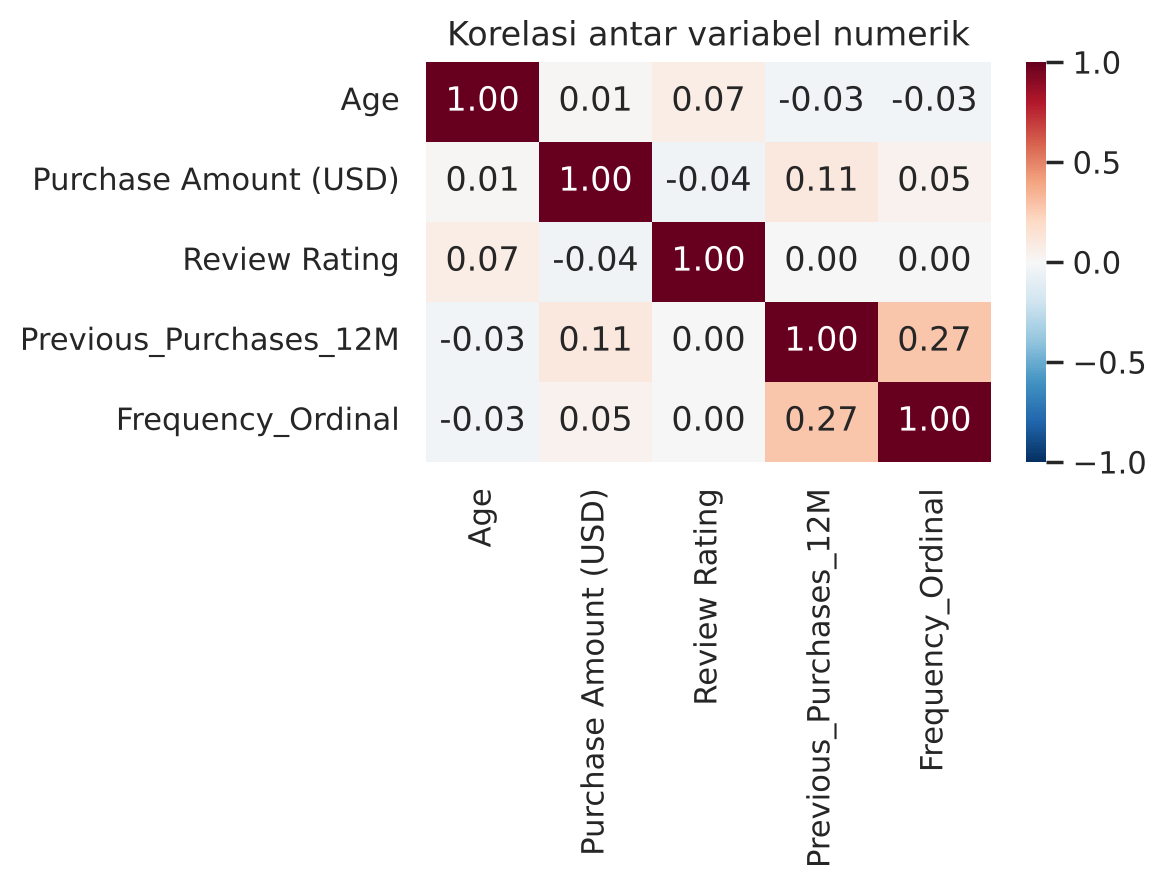

In [14]:
prop1 = X.drop(columns=num_cols).mean()
rendah = prop1[(prop1 < 0.05) | (prop1 > 0.95)]
M["varians_rendah"] = {k: round(float(v), 3) for k, v in rendah.items()}
print("Fitur varians rendah:", M["varians_rendah"])
X_sel = X.drop(columns=rendah.index)

kor = fe[num_cols].corr()
pasangan = [(a, b, round(float(kor.loc[a, b]), 2)) for i, a in enumerate(num_cols) for b in num_cols[i + 1:] if abs(kor.loc[a, b]) > 0.8]
M["kor_tinggi"] = pasangan
M["kor_maks"] = float(kor.where(~np.eye(len(kor), dtype=bool)).abs().max().max())
print("Pasangan |r| > 0,8:", pasangan, "| |r| maksimum:", round(M["kor_maks"], 2))
plt.figure(figsize=(6, 4.6)); sns.heatmap(kor, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Korelasi antar variabel numerik"); simpan_gambar("03_korelasi")
M["X_setelah_varians"] = int(X_sel.shape[1])

,Mutual information
Subscription_Yes,0.056
Season_Winter,0.048
Age,0.047
Category_Footwear,0.025
Payment_Method_Debit_Card,0.018
Shipping_Type_Free_Shipping,0.017
Payment_Method_Credit_Card,0.012
Shipping_Type_Express,0.011
Payment_Method_PayPal,0.006
Payment_Method_Tidak_Diketahui,0.000


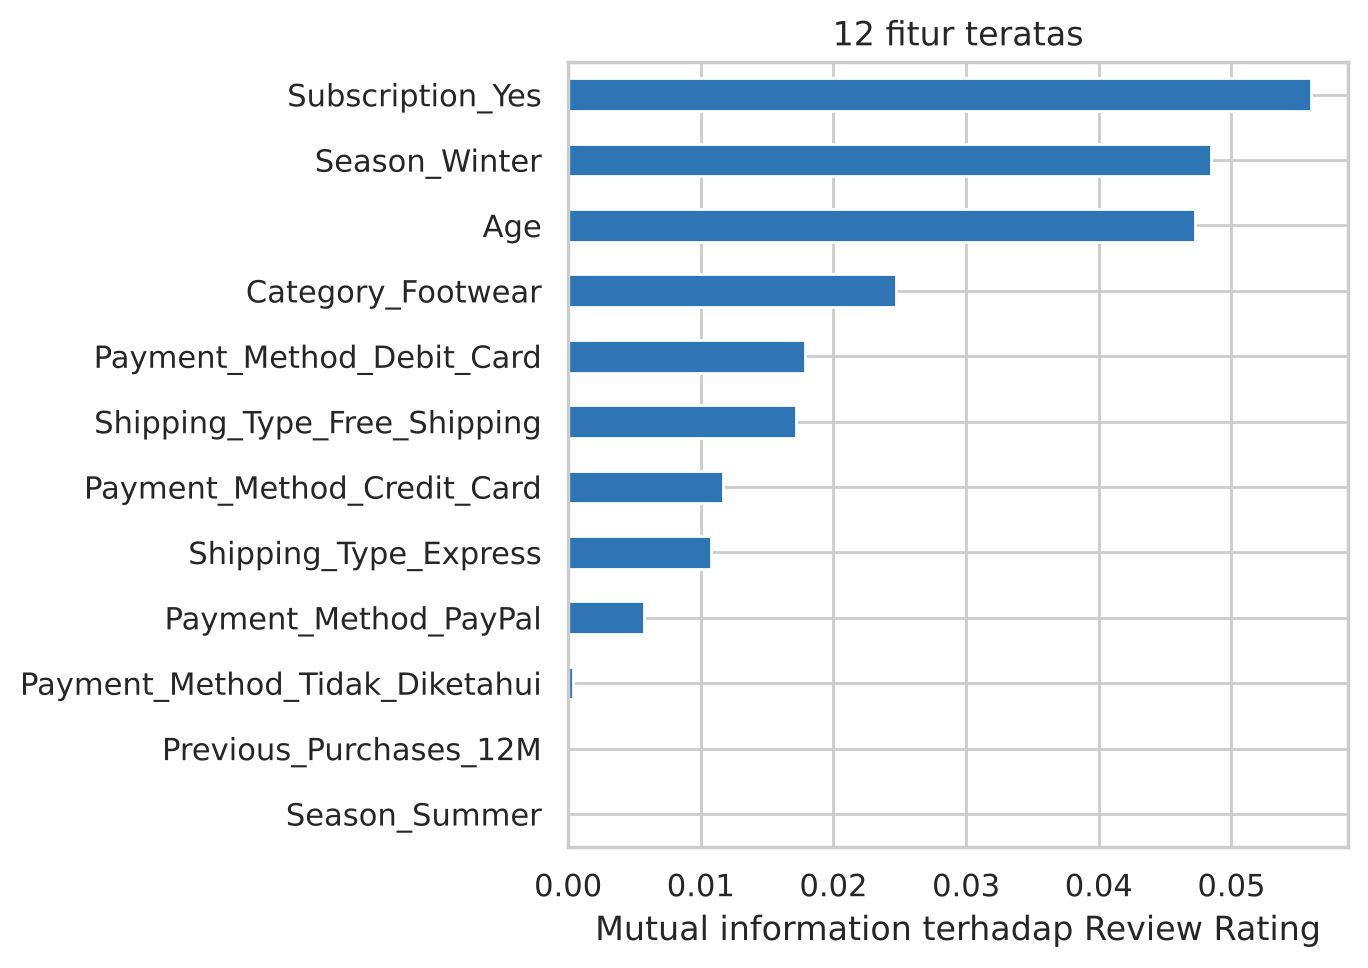

In [15]:
from sklearn.feature_selection import mutual_info_regression
y_rating = df["Review Rating"].values
fitur = [c for c in X_sel.columns if c != "Review Rating"]
diskrit = np.array([c not in num_cols for c in fitur])
mi = pd.Series(mutual_info_regression(X_sel[fitur].values, y_rating, discrete_features=diskrit, random_state=42), index=fitur).sort_values(ascending=False)
M["mi"] = {k: round(float(v), 3) for k, v in mi.items()}
M["mi_top10"] = list(mi.head(10).index)
display(mi.head(10).round(3).to_frame("Mutual information"))
plt.figure(figsize=(7, 5)); mi.head(12).iloc[::-1].plot.barh(color="#2E75B6")
plt.xlabel("Mutual information terhadap Review Rating"); plt.title("12 fitur teratas"); simpan_gambar("04_mutual_info")

### 5.2 Ekstraksi Fitur dengan PCA
**Input:** `X_sel`, yaitu seluruh fitur setelah filter varians.
**Proses:** standardisasi semua kolom (termasuk dummy) lalu PCA. Jumlah komponen dipilih agar varians kumulatif >= 80%.
**Output:** `hasil/hasil_pca.csv` (skor komponen utama) dan tabel *loading*.

{'n_fitur': 28, 'n80': 16, 'n90': 19, 'var_pc': [7.8, 6.9, 6.8, 6.6, 6.1], 'kum_n80': 82.2}


,PC1,PC2,PC3
Frequency_Ordinal,-0.13,0.05,0.38
Season_Summer,0.07,0.37,0.10
Shipping_Type_Free_Shipping,0.35,0.15,-0.25
Previous_Purchases_12M,-0.24,-0.04,0.35
Payment_Method_Cash,-0.07,-0.33,-0.02
Shipping_Type_Express,0.09,0.06,0.32
Region_West,-0.32,0.12,-0.11
Region_South,0.32,-0.26,0.16


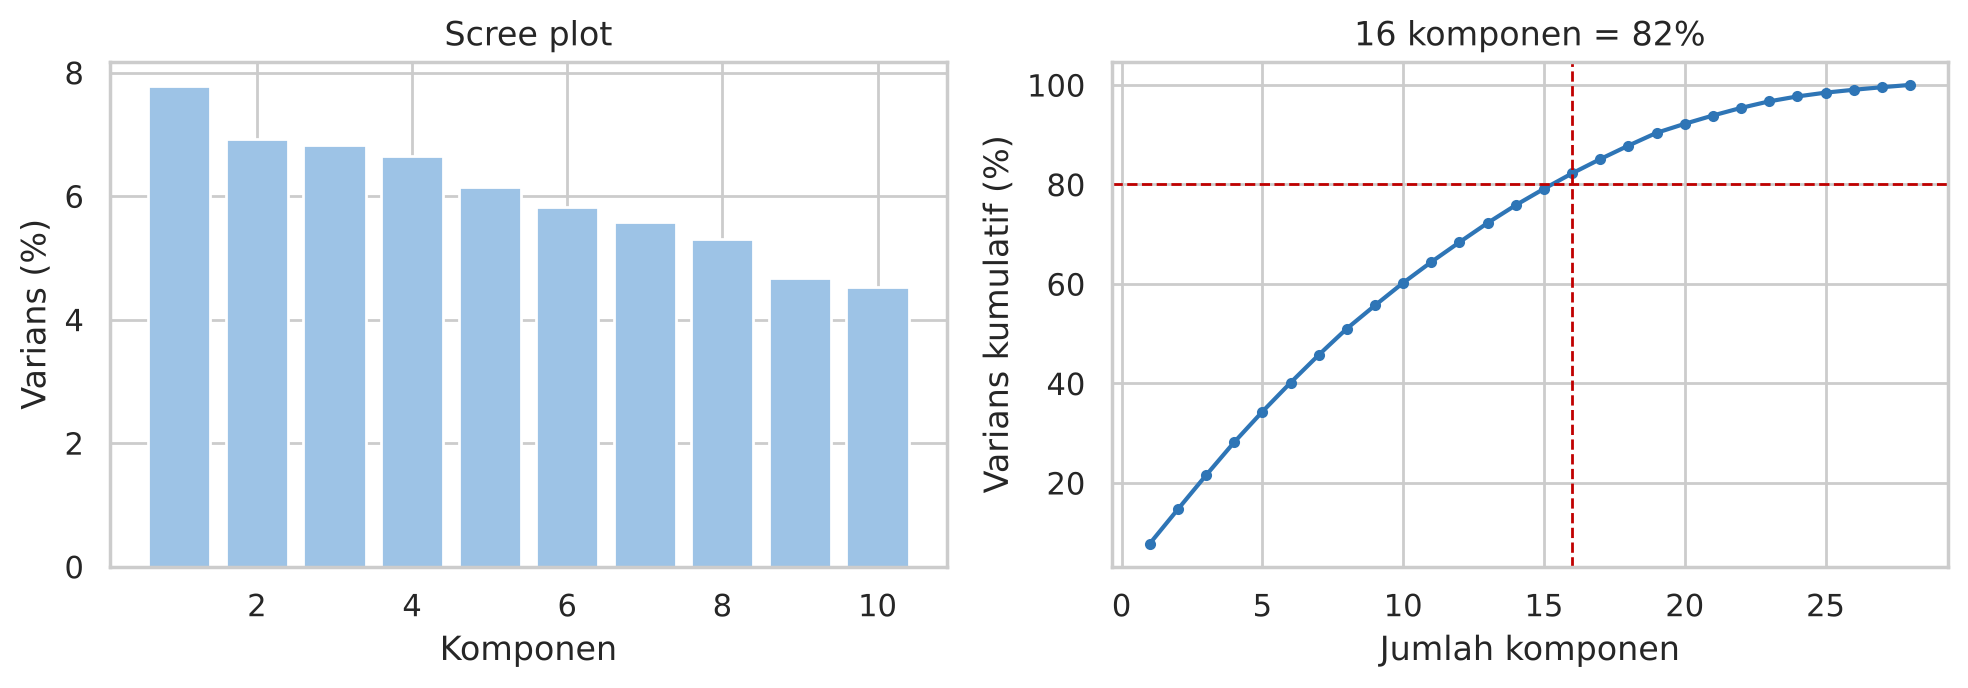

Dimensi:  28 -> 28 (seleksi) -> 16 (PCA 80%)


In [16]:
from sklearn.decomposition import PCA
Z = StandardScaler().fit_transform(X_sel)
pca = PCA(random_state=42).fit(Z)
kum = np.cumsum(pca.explained_variance_ratio_)
n80, n90 = int(np.argmax(kum >= 0.80) + 1), int(np.argmax(kum >= 0.90) + 1)
M["pca"] = {"n_fitur": int(Z.shape[1]), "n80": n80, "n90": n90,
            "var_pc": [round(float(v) * 100, 1) for v in pca.explained_variance_ratio_[:5]], "kum_n80": round(float(kum[n80 - 1]) * 100, 1)}
print(M["pca"])
load = pd.DataFrame(pca.components_[:3].T, index=X_sel.columns, columns=["PC1", "PC2", "PC3"])
M["loading"] = {pc: [[k, round(float(load.loc[k, pc]), 2)] for k in load[pc].abs().sort_values(ascending=False).head(4).index] for pc in load.columns}
display(load.round(2).loc[load.abs().max(axis=1).sort_values(ascending=False).head(8).index])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(range(1, 11), pca.explained_variance_ratio_[:10] * 100, color="#9DC3E6"); ax[0].set_xlabel("Komponen"); ax[0].set_ylabel("Varians (%)"); ax[0].set_title("Scree plot")
ax[1].plot(range(1, len(kum) + 1), kum * 100, marker="o", ms=3, color="#2E75B6"); ax[1].axhline(80, color="#C00000", ls="--", lw=1)
ax[1].axvline(n80, color="#C00000", ls="--", lw=1); ax[1].set_xlabel("Jumlah komponen"); ax[1].set_ylabel("Varians kumulatif (%)"); ax[1].set_title(f"{n80} komponen = {kum[n80-1]*100:.0f}%")
simpan_gambar("05_pca")

pd.DataFrame(pca.transform(Z)[:, :n80], columns=[f"PC{i+1}" for i in range(n80)]).to_csv("hasil/hasil_pca.csv", index=False)
X_sel.to_csv("hasil/data_siap_model.csv", index=False)
M["X_akhir"] = list(X_sel.columns)
print("Dimensi: ", X.shape[1], "->", X_sel.shape[1], "(seleksi) ->", n80, "(PCA 80%)")

## 6. Ringkasan Sebelum dan Sesudah Preprocessing

In [17]:
ring = pd.DataFrame({
    "Aspek": ["Jumlah baris", "Jumlah kolom", "Total missing value", "Baris duplikat", "Kolom bertipe teks salah (numerik)", "Dimensi fitur untuk model"],
    "Sebelum": [df_raw.shape[0], df_raw.shape[1], int(df_raw.isna().sum().sum()), M["duplikat_awal"], 3, df_raw.shape[1] - 1],
    "Sesudah": [df.shape[0], df.shape[1], int(df.isna().sum().sum()), int(df.duplicated().sum()), 0, f"{X_sel.shape[1]} (PCA: {n80})"]})
display(ring)
M["ringkasan"] = ring.to_dict("records"); M["shape_bersih"] = list(df.shape); M["missing_total_awal"] = int(df_raw.isna().sum().sum())
with open("hasil_metrik.json", "w", encoding="utf-8") as f:
    json.dump(M, f, ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))

,Aspek,Sebelum,Sesudah
0,Jumlah baris,120,115
1,Jumlah kolom,14,13
2,Total missing value,53,0
3,Baris duplikat,5,0
4,Kolom bertipe teks salah (numerik),3,0
5,Dimensi fitur untuk model,13,28 (PCA: 16)
